# 🧬 Deep Learning for Cancer Drug Response Prediction

### Pipeline
**Real Data → Cleaning → EDA → Feature Engineering → Split → Neural Network → Regularization → Hyperparameter Search → Evaluation → Explainability → Save Model → FastAPI → Docker**


In [1]:
# 0) نصب کتابخانه‌ها
%pip install -q pandas numpy scikit-learn matplotlib seaborn tensorflow joblib fastapi uvicorn[standard] python-multipart


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# 1) Imports
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    roc_auc_score, classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


## 2) دریافت دیتاست واقعی



In [3]:
!pip install kagglehub

In [4]:
import sys
print(sys.executable)

c:\Users\ASUS.PIESC\AppData\Local\Programs\Python\Python313\python.exe


In [5]:
import sys
!{sys.executable} -m pip install kagglehub


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
pip install --upgrade kaggle

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import requests
from pathlib import Path
from tqdm import tqdm

# ============================================================
# مسیر ذخیره فایل‌ها
# ============================================================
DATA_DIR = Path("gdsc_data")
DATA_DIR.mkdir(exist_ok=True)

# ============================================================
# آدرس پایه‌ی FTP رسمی Sanger Institute (بدون محدودیت جغرافیایی)
# ============================================================
BASE_URL = "https://ftp.sanger.ac.uk/pub/project/cancerrxgene/releases/current_release/"

# فایل‌های اصلی موردنیاز پروژه:
#  - GDSC2_fitted_dose_response: پاسخ به دارو (IC50, AUC) -> متغیر هدف
#  - Cell_Lines_Details: ویژگی‌های رده‌های سلولی (بافت، نوع سرطان و ...)
#  - screened_compounds: اطلاعات داروهای غربالگری‌شده
FILES = {
    "GDSC2_fitted_dose_response.xlsx": "GDSC2_fitted_dose_response_24Jul22.xlsx",
    "Cell_Lines_Details.xlsx": "Cell_Lines_Details.xlsx",
    "screened_compounds.csv": "screened_compounds_rel_8.4.csv",
}


def download_file(url: str, dest: Path):
    """دانلود فایل با نمایش پیشرفت"""
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total_size = int(r.headers.get("content-length", 0))

        with open(dest, "wb") as f, tqdm(
            total=total_size,
            unit="B",
            unit_scale=True,
            desc=dest.name,
        ) as pbar:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
                pbar.update(len(chunk))


# ============================================================
# دانلود همه‌ی فایل‌ها
# ============================================================
for local_name, remote_name in FILES.items():
    dest_path = DATA_DIR / local_name
    url = BASE_URL + remote_name

    if dest_path.exists():
        print(f"✔ {local_name} از قبل موجود است، رد شد.")
        continue

    print(f"در حال دانلود: {remote_name}")
    try:
        download_file(url, dest_path)
        print(f"✅ ذخیره شد: {dest_path}\n")
    except Exception as e:
        print(f"❌ خطا در دانلود {remote_name}: {e}\n")

print("\nهمه‌ی فایل‌ها بررسی شدند.")

✔ GDSC2_fitted_dose_response.xlsx از قبل موجود است، رد شد.
✔ Cell_Lines_Details.xlsx از قبل موجود است، رد شد.
✔ screened_compounds.csv از قبل موجود است، رد شد.

همه‌ی فایل‌ها بررسی شدند.


In [8]:
import pandas as pd

# پاسخ به دارو (متغیر هدف اصلی پروژه)
df_response = pd.read_excel(DATA_DIR / "GDSC2_fitted_dose_response.xlsx")

# اطلاعات رده‌های سلولی
df_cell_lines = pd.read_excel(DATA_DIR / "Cell_Lines_Details.xlsx")

# اطلاعات داروها
df_compounds = pd.read_csv(DATA_DIR / "screened_compounds.csv")

print(df_response.shape)
df_response.head()

(242036, 19)


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,COSMIC_ID,CELL_LINE_NAME,SANGER_MODEL_ID,TCGA_DESC,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,COMPANY_ID,WEBRELEASE,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,401,18945558,683667,PFSK-1,SIDM01132,MB,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-1.462148,0.930105,0.088999,0.432482
1,GDSC2,401,18945796,684052,A673,SIDM00848,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-4.869447,0.614932,0.111423,-1.420322
2,GDSC2,401,18946078,684057,ES5,SIDM00263,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-3.360684,0.790953,0.142754,-0.599894
3,GDSC2,401,18946335,684059,ES7,SIDM00269,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-5.045014,0.592624,0.135642,-1.515791
4,GDSC2,401,18946617,684062,EW-11,SIDM00203,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-3.741620,0.733992,0.128066,-0.807038


In [9]:
# # 3) Inspect dataset
# print(df.shape)
# display(df.head())
# display(df.dtypes.head(30))

import pandas as pd
from pathlib import Path

DATA_DIR = Path("gdsc_data")

# ============================================================
# بارگذاری هر سه فایل
# ============================================================
df_response = pd.read_excel(DATA_DIR / "GDSC2_fitted_dose_response.xlsx")
df_cell_lines = pd.read_excel(DATA_DIR / "Cell_Lines_Details.xlsx")
df_compounds = pd.read_csv(DATA_DIR / "screened_compounds.csv")

# ============================================================
# پاک‌سازی نام ستون‌ها (حذف \n و فاصله‌های اضافی)
# ============================================================
df_cell_lines.columns = (
    df_cell_lines.columns
    .str.replace("\n", " ", regex=False)
    .str.strip()
)

# ============================================================
# Merge 1: افزودن اطلاعات رده‌های سلولی
# ============================================================
df = df_response.merge(
    df_cell_lines,
    left_on="COSMIC_ID",
    right_on="COSMIC identifier",
    how="left"
)

# ============================================================
# Merge 2: افزودن اطلاعات تکمیلی دارو
# (DRUG_NAME تکراریه، پس فقط ستون‌های اضافی رو می‌گیریم)
# ============================================================
df_compounds_extra = df_compounds[
    ["DRUG_ID", "SCREENING_SITE", "SYNONYMS", "TARGET", "TARGET_PATHWAY"]
]

df = df.merge(
    df_compounds_extra,
    on="DRUG_ID",
    how="left"
)

# ============================================================
# حذف ستون تکراری COSMIC identifier (چون COSMIC_ID رو داریم)
# ============================================================
df = df.drop(columns=["COSMIC identifier"], errors="ignore")

# 3) Inspect dataset
print(df.shape)
display(df.head())
display(df.dtypes.head(30))

(242036, 35)


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,COSMIC_ID,CELL_LINE_NAME,SANGER_MODEL_ID,TCGA_DESC,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,...,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,SCREENING_SITE,SYNONYMS,TARGET,TARGET_PATHWAY
0,GDSC2,401,18945558,683667,PFSK-1,SIDM01132,MB,1003,Camptothecin,TOP1,...,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,SANGER,"Camptothecine, (+)-Camptothecin",TOP1,DNA replication
1,GDSC2,401,18945796,684052,A673,SIDM00848,UNCLASSIFIED,1003,Camptothecin,TOP1,...,soft_tissue,rhabdomyosarcoma,NaN,MSS/MSI-L,D/F12,Adherent,SANGER,"Camptothecine, (+)-Camptothecin",TOP1,DNA replication
2,GDSC2,401,18946078,684057,ES5,SIDM00263,UNCLASSIFIED,1003,Camptothecin,TOP1,...,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,SANGER,"Camptothecine, (+)-Camptothecin",TOP1,DNA replication
3,GDSC2,401,18946335,684059,ES7,SIDM00269,UNCLASSIFIED,1003,Camptothecin,TOP1,...,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,SANGER,"Camptothecine, (+)-Camptothecin",TOP1,DNA replication
4,GDSC2,401,18946617,684062,EW-11,SIDM00203,UNCLASSIFIED,1003,Camptothecin,TOP1,...,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,SANGER,"Camptothecine, (+)-Camptothecin",TOP1,DNA replication


DATASET                                      object
NLME_RESULT_ID                                int64
NLME_CURVE_ID                                 int64
COSMIC_ID                                     int64
CELL_LINE_NAME                               object
SANGER_MODEL_ID                              object
TCGA_DESC                                    object
DRUG_ID                                       int64
DRUG_NAME                                    object
PUTATIVE_TARGET                              object
PATHWAY_NAME                                 object
COMPANY_ID                                    int64
WEBRELEASE                                   object
MIN_CONC                                    float64
MAX_CONC                                    float64
LN_IC50                                     float64
AUC                                         float64
RMSE                                        float64
Z_SCORE                                     float64
Sample Name 

In [10]:
print(df_response.columns.tolist())
print(df_cell_lines.columns.tolist())
print(df_compounds.columns.tolist())

['DATASET', 'NLME_RESULT_ID', 'NLME_CURVE_ID', 'COSMIC_ID', 'CELL_LINE_NAME', 'SANGER_MODEL_ID', 'TCGA_DESC', 'DRUG_ID', 'DRUG_NAME', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'COMPANY_ID', 'WEBRELEASE', 'MIN_CONC', 'MAX_CONC', 'LN_IC50', 'AUC', 'RMSE', 'Z_SCORE']
['Sample Name', 'COSMIC identifier', 'Whole Exome Sequencing (WES)', 'Copy Number Alterations (CNA)', 'Gene Expression', 'Methylation', 'Drug Response', 'GDSC Tissue descriptor 1', 'GDSC Tissue descriptor 2', 'Cancer Type (matching TCGA label)', 'Microsatellite  instability Status (MSI)', 'Screen Medium', 'Growth Properties']
['DRUG_ID', 'SCREENING_SITE', 'DRUG_NAME', 'SYNONYMS', 'TARGET', 'TARGET_PATHWAY']


In [11]:
# 4) Identify likely target column
# نام ستون پاسخ ممکن است بسته به نسخه دیتاست متفاوت باشد.
candidate_targets = [
    "LN_IC50", "IC50", "ln_ic50", "AUC", "auc",
    "response", "drug_response", "Response"
]

target_candidates = [c for c in candidate_targets if c in df.columns]
print("Possible target columns:", target_candidates)

if not target_candidates:
    print("All columns:")
    print(df.columns.tolist())
    raise ValueError("Target column not found. Choose the response column manually.")

TARGET = target_candidates[0]
print("Selected target:", TARGET)


Possible target columns: ['LN_IC50', 'AUC']
Selected target: LN_IC50


In [12]:
# 5) Basic data quality analysis
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "n_unique": df.nunique()
}).sort_values("missing_pct", ascending=False)

display(quality.head(30))


,dtype,missing,missing_pct,n_unique
SYNONYMS,object,63828,26.371284,207
Cancer Type (matching TCGA label),object,43514,17.978317,31
PUTATIVE_TARGET,object,27155,11.219405,185
TARGET,object,27155,11.219405,185
Microsatellite instability Status (MSI),object,2987,1.234114,2
TCGA_DESC,object,1067,0.440844,32
DATASET,object,0,0.000000,1
NLME_CURVE_ID,int64,0,0.000000,242036
NLME_RESULT_ID,int64,0,0.000000,1
CELL_LINE_NAME,object,0,0.000000,969


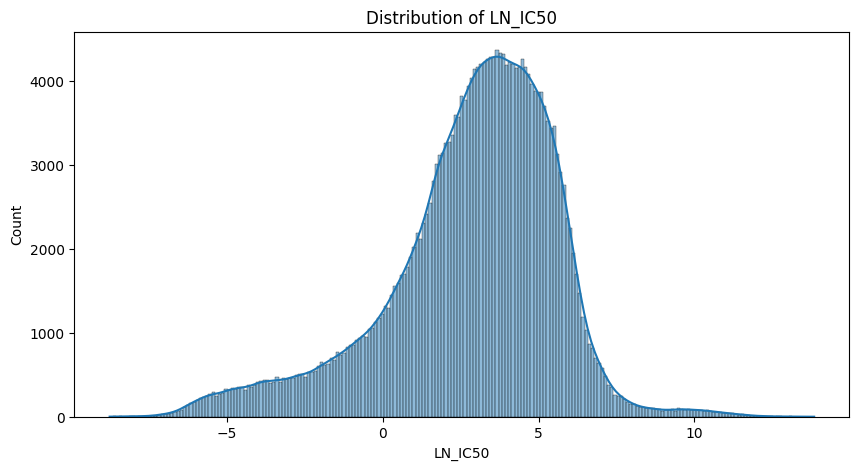

count    242036.000000
mean          2.833780
std           2.760679
min          -8.769011
25%           1.521444
50%           3.255135
75%           4.714123
max          13.847363
Name: LN_IC50, dtype: float64


In [13]:
# 6) Target distribution
plt.figure(figsize=(10,5))
sns.histplot(df[TARGET].dropna(), kde=True)
plt.title(f"Distribution of {TARGET}")
plt.xlabel(TARGET)
plt.show()

print(df[TARGET].describe())


## 3) Feature engineering

داده‌های سرطان معمولاً ترکیبی از:
- شناسه سلول/بیمار
- شناسه دارو
- ویژگی‌های مولکولی
- متادیتا
- پاسخ دارویی

هستند.

برای جلوگیری از leakage، ستون‌های شناسه‌ای که مستقیماً پاسخ را لو می‌دهند وارد مدل نمی‌کنیم.


In [14]:
# 7) Prepare numeric features
data = df.copy()
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=[TARGET])

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_cols if c != TARGET]

# Remove obvious identifier-like numeric columns
drop_numeric = []
for c in numeric_features:
    nunique = data[c].nunique()
    if nunique <= 1:
        drop_numeric.append(c)

numeric_features = [c for c in numeric_features if c not in drop_numeric]

print("Number of numeric features:", len(numeric_features))
print("First features:", numeric_features[:20])


Number of numeric features: 9
First features: ['NLME_CURVE_ID', 'COSMIC_ID', 'DRUG_ID', 'COMPANY_ID', 'MIN_CONC', 'MAX_CONC', 'AUC', 'RMSE', 'Z_SCORE']


In [15]:
# 8) Optional categorical summary
categorical_cols = data.select_dtypes(include=["object","category"]).columns.tolist()
print("Categorical columns:", categorical_cols[:30])


Categorical columns: ['DATASET', 'CELL_LINE_NAME', 'SANGER_MODEL_ID', 'TCGA_DESC', 'DRUG_NAME', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'WEBRELEASE', 'Sample Name', 'Whole Exome Sequencing (WES)', 'Copy Number Alterations (CNA)', 'Gene Expression', 'Methylation', 'Drug Response', 'GDSC Tissue descriptor 1', 'GDSC Tissue descriptor 2', 'Cancer Type (matching TCGA label)', 'Microsatellite  instability Status (MSI)', 'Screen Medium', 'Growth Properties', 'SCREENING_SITE', 'SYNONYMS', 'TARGET', 'TARGET_PATHWAY']


In [16]:
# 9) Train/validation/test split
X = data[numeric_features].copy()
y = data[TARGET].astype("float32").copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (169425, 9)
Validation: (36305, 9)
Test: (36306, 9)


In [17]:
# 10) Imputation + scaling
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

print(X_train_scaled.shape)


(169425, 9)


## 4) Deep Neural Network

مدل شامل:
- Dense layers
- Batch Normalization
- ReLU
- Dropout
- L2 regularization
- Adam optimizer

است.


In [ ]:
# 11) Build neural network
def build_model(input_dim, units1=180, units2=90, dropout=0.30, lr=1e-3):
    from tensorflow import keras
from tensorflow.keras import layers

# 11) Build neural network
def build_model(input_dim, units1=64, units2=32, dropout=0.40, l2=1e-3, lr=1e-3):
    # منظم‌سازی یکسان برای همهٔ لایه‌های پنهان
    reg = keras.regularizers.l2(l2)

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),

        layers.Dense(units1, kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(dropout),

        layers.Dense(units2, kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(dropout),

        layers.Dense(1)  # لایهٔ خروجی رگرسیون، بدون فعال‌ساز
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.Huber(delta=1.0),  # نسبت به داده‌های پرت مقاوم‌تر از MSE
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model


model = build_model(X_train_scaled.shape[1])


model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 192 (768.00 B)

In [30]:
# 12) Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.4,
        patience=4,
        min_lr=1e-6
    ),
    keras.callbacks.ModelCheckpoint(
        "models/best_drug_response.keras",
        monitor="val_loss",
        save_best_only=True
    )
]


In [31]:
# 13) Train
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=256,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.1705 - mae: 1.5422 - val_loss: 0.6849 - val_mae: 1.0360 - learning_rate: 0.0010
Epoch 2/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.7626 - mae: 1.1168 - val_loss: 0.5523 - val_mae: 0.8613 - learning_rate: 0.0010
Epoch 3/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6427 - mae: 0.9862 - val_loss: 0.5945 - val_mae: 0.9174 - learning_rate: 0.0010
Epoch 4/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.5875 - mae: 0.9288 - val_loss: 0.6254 - val_mae: 0.9624 - learning_rate: 0.0010
Epoch 5/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5565 - mae: 0.8990 - val_loss: 0.6239 - val_mae: 0.9639 - learning_rate: 0.0010
Epoch 6/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5399 - mae: 0.8833 - val_loss: 0.6394 - val_mae: 0.9833 - learning_rate: 0.0010
Epoch 7/100
662/662 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5181 - mae: 0.8608 - val_loss: 0.6398 - val_mae: 0.9869 - learning_rate: 4.0000

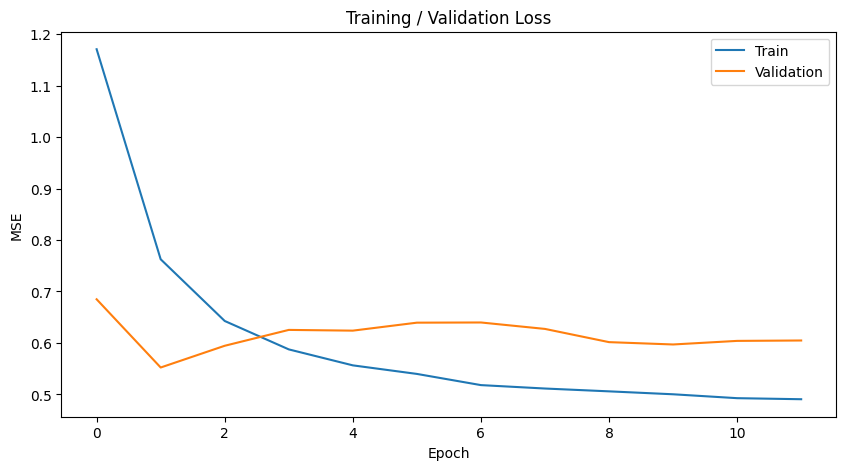

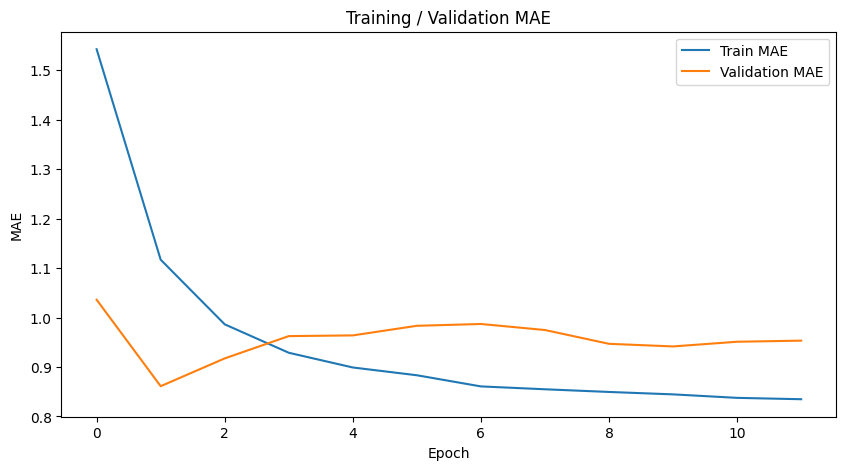

In [32]:
# 14) Training curves
h = pd.DataFrame(history.history)

plt.figure(figsize=(10,5))
plt.plot(h["loss"], label="Train")
plt.plot(h["val_loss"], label="Validation")
plt.title("Training / Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(h["mae"], label="Train MAE")
plt.plot(h["val_mae"], label="Validation MAE")
plt.title("Training / Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.show()


## 5) ارزیابی



In [33]:
# 15) Evaluation
pred = model.predict(X_test_scaled, verbose=0).ravel()

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})
display(metrics)


,Metric,Value
0,MAE,0.858575
1,RMSE,1.362885
2,R2,0.758363


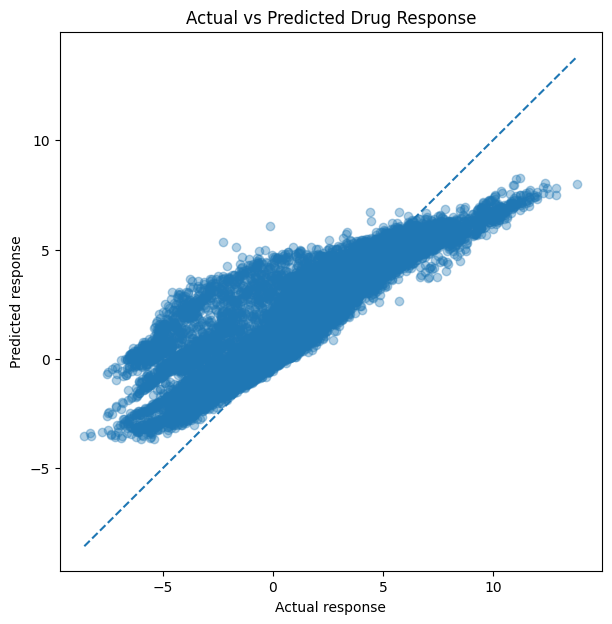

In [34]:
# 16) Actual vs predicted
plt.figure(figsize=(7,7))
plt.scatter(y_test, pred, alpha=0.35)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Actual response")
plt.ylabel("Predicted response")
plt.title("Actual vs Predicted Drug Response")
plt.show()


## 6) تبدیل مسئله به Responder / Non-responder




In [35]:
# 17) Research-only responder classification
threshold = float(np.median(y_train))

y_test_bin = (y_test <= threshold).astype(int)
pred_prob = 1 / (1 + np.exp(pred))  # monotonic transformation for ranking
# بهتر: min-max rank-like normalization for AUC
pred_prob = (pred.max() - pred) / (pred.max() - pred.min() + 1e-8)

auc = roc_auc_score(y_test_bin, pred_prob)
print("Research-only threshold:", threshold)
print("ROC-AUC:", auc)


Research-only threshold: 3.254059076309204
ROC-AUC: 0.9678145337292062


                       precision    recall  f1-score   support

Higher-response group       0.84      0.97      0.90     18302
 Lower-response group       0.96      0.81      0.88     18004

             accuracy                           0.89     36306
            macro avg       0.90      0.89      0.89     36306
         weighted avg       0.90      0.89      0.89     36306



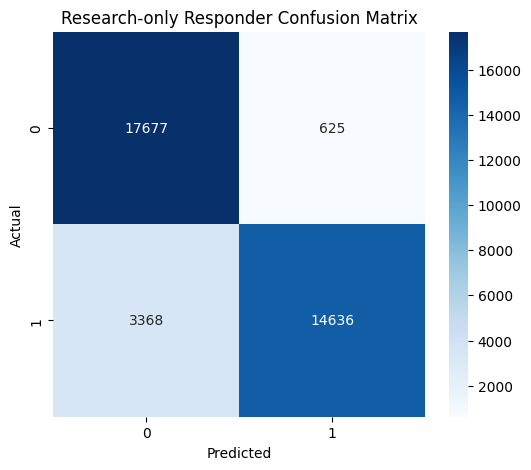

In [36]:
# 18) Classification report
pred_bin = (pred <= threshold).astype(int)

print(classification_report(
    y_test_bin,
    pred_bin,
    target_names=["Higher-response group", "Lower-response group"]
))

cm = confusion_matrix(y_test_bin, pred_bin)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Research-only Responder Confusion Matrix")
plt.show()


## 7) Feature importance تقریبی

برای شبکه عصبی، feature importance ساده و قطعی مانند درخت تصمیم نداریم. اینجا از permutation importance استفاده می‌کنیم تا ببینیم تغییر هر feature چه اثری بر خطا دارد.


,feature,importance
6,AUC,5.412556
5,MAX_CONC,0.639489
4,MIN_CONC,0.534025
8,Z_SCORE,0.525288
3,COMPANY_ID,0.093063
1,COSMIC_ID,0.068388
2,DRUG_ID,0.063152
7,RMSE,0.059417
0,NLME_CURVE_ID,0.049427


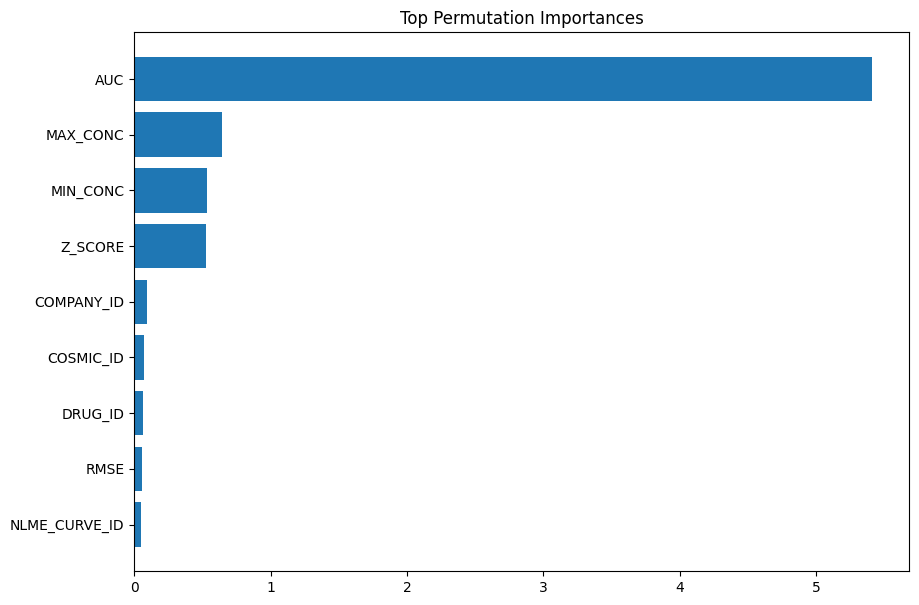

In [57]:
# 19) Permutation importance on a manageable sample
from sklearn.inspection import permutation_importance

sample_n = min(1000, len(X_test_scaled))
X_perm = X_test_scaled[:sample_n]
y_perm = y_test.iloc[:sample_n]

class Wrapper:
    def predict(self, X):
        return model.predict(X, verbose=0).ravel()

wrapper = Wrapper()

# permutation_importance expects estimator.score; build a lightweight sklearn-compatible wrapper
class KerasRegressorWrapper:
    def fit(self, X, y): return self
    def predict(self, X): return model.predict(X, verbose=0).ravel()
    def score(self, X, y):
        p = self.predict(X)
        return -mean_squared_error(y, p)

perm = permutation_importance(
    KerasRegressorWrapper(),
    X_perm, y_perm,
    scoring="neg_mean_squared_error",
    n_repeats=3,
    random_state=SEED
)

importance = pd.DataFrame({
    "feature": numeric_features,
    "importance": perm.importances_mean
}).sort_values("importance", ascending=False)

display(importance.head(20))

plt.figure(figsize=(10,7))
top = importance.head(15).sort_values("importance")
plt.barh(top["feature"], top["importance"])
plt.title("Top Permutation Importances")
plt.show()


## 8) ذخیره preprocessing و مدل




In [43]:

import os
import json
import joblib

os.makedirs("models", exist_ok=True)

model.save("models/final_model.keras")
joblib.dump(imputer, "models/imputer.joblib")
joblib.dump(scaler, "models/scaler.joblib")

with open("models/features.json", "w", encoding="utf-8") as f:
    # تبدیل به list تا در صورت pandas.Index بودن، json بتواند serialize کند
    json.dump(list(numeric_features), f, ensure_ascii=False, indent=2)

with open("models/config.json", "w", encoding="utf-8") as f:
    json.dump({
        "target": TARGET,
        "threshold_research_only": float(threshold),  # تبدیل از numpy به float خالص
        "model_type": "Dense Neural Network",
        "warning": "Research/education only; not clinical decision support."
    }, f, ensure_ascii=False, indent=2)

print("Artifacts saved.")


Artifacts saved.


## 9) تست inference

تابع زیر یک ردیف ویژگی را گرفته و پاسخ پیش‌بینی‌شده را برمی‌گرداند.


In [41]:
# 21) Inference helper
def predict_response(row_dict):
    row = pd.DataFrame([row_dict])
    row = row.reindex(columns=numeric_features)

    row_imp = imputer.transform(row)
    row_scaled = scaler.transform(row_imp)

    prediction = float(model.predict(row_scaled, verbose=0).ravel()[0])
    return prediction

# Example using first test row:
example = X_test.iloc[0].to_dict()
print("Predicted response:", predict_response(example))


Predicted response: 1.287696123123169
